DIABETES PREVALENCE FORECASTING - INDONESIA

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        4.09
1991        4.07
1992        4.06
1993        4.06
1994        4.06

Last 5 rows:
      Prevalence
Year            
2018        9.58
2019       10.30
2020       11.06
2021       11.86
2022       12.71

UJI STASIONERITAS (Augmented Dickey-Fuller Test)
ADF Statistic: -3.9928
p-value: 0.0014
Critical Values:
	1%: -3.770
	5%: -3.005
	10%: -2.643

✓ Data STASIONER (p-value < 0.05)

Training set: 26 observations (1990 - 2015)
Test set: 7 observations (2016 - 2022)

PENCARIAN PARAMETER ARIMA TERBAIK

Top 5 Model ARIMA berdasarkan AIC:
 p  d  q         AIC
 2  2  0 -149.569450
 1  2  3 -148.641968
 3  2  0 -148.446887
 2  2  1 -148.429300
 3  2  2 -148.420551

✓ Model Terbaik: ARIMA(2, 2, 0)
  AIC: -149.5695

MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:             

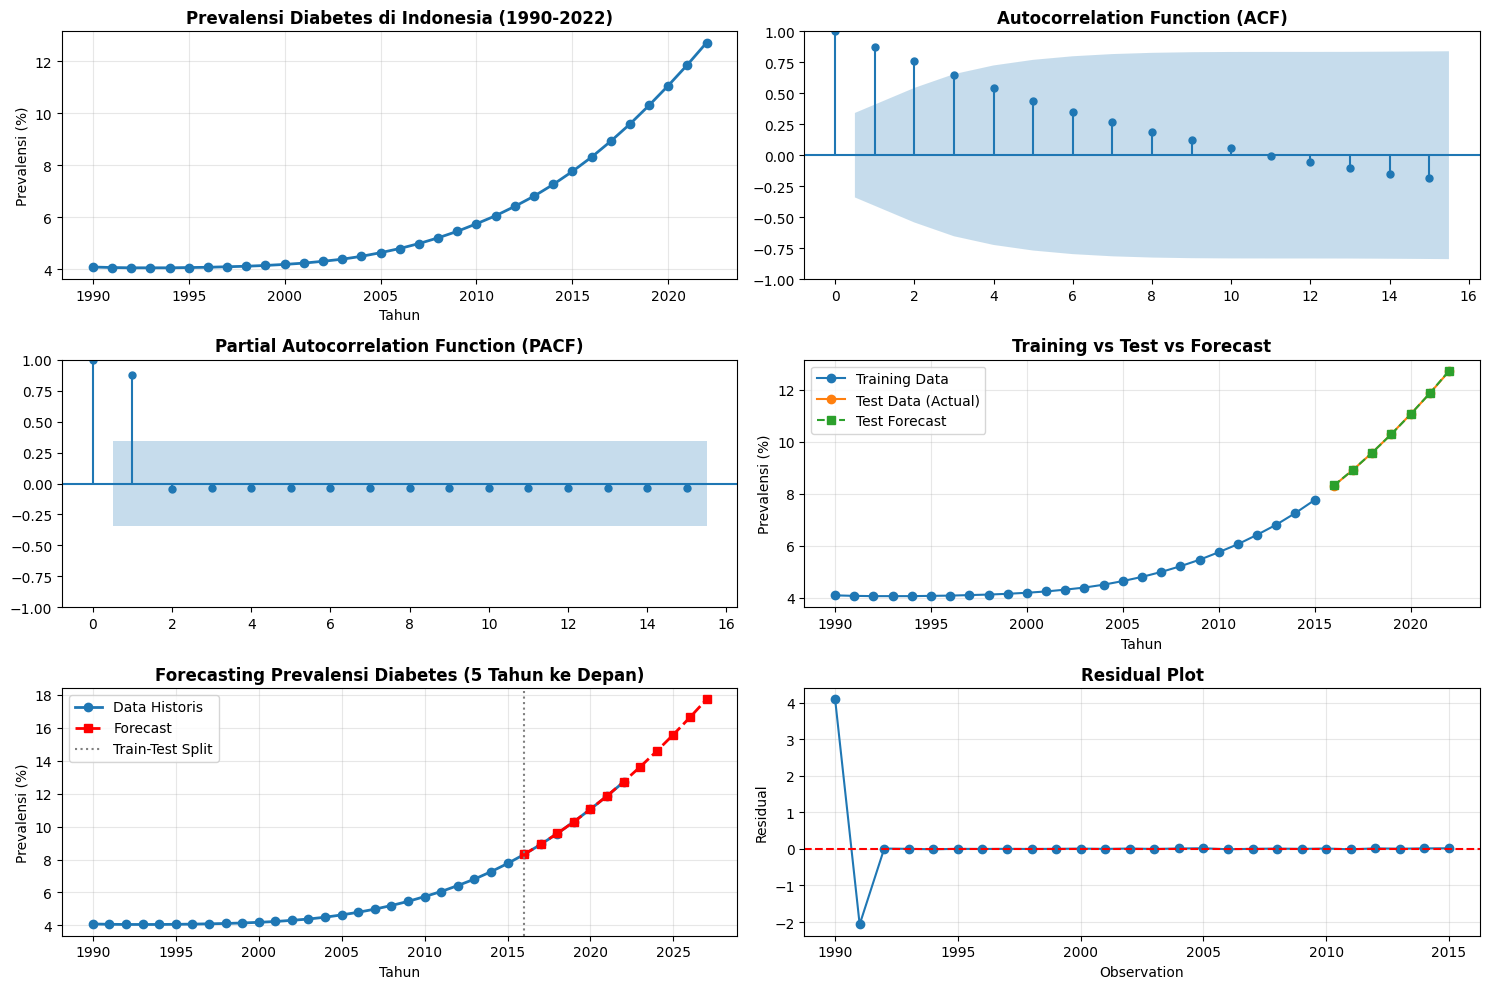


HASIL FORECASTING

Forecast untuk Test Set:
 Year  Forecasted_Prevalence
 2016               8.316905
 2017               8.923438
 2018               9.584261
 2019              10.294026
 2020              11.055815
 2021              11.865651
 2022              12.725508

PREDIKSI 5 TAHUN KE DEPAN (2023-2027)
 Year  Forecasted_Prevalence
 2023              13.632380
 2024              14.587464
 2025              15.588446
 2026              16.635982
 2027              17.728253

✓ Hasil forecasting disimpan ke 'diabetes_forecast_results.csv'

INTERPRETASI

1. Tren prevalensi diabetes: MENINGKAT
2. Perubahan dari 2022 ke 2027: +39.48%
3. Prevalensi 2022 (aktual): 12.71%
4. Prediksi prevalensi 2027: 17.73%

⚠️  Model accuracy (MAPE): nan%
   → Perlu perbaikan model

ANALISIS SELESAI


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Load data
df = pd.read_csv ('data_psd.csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - INDONESIA")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Indonesia (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

# ACF and PACF plots (max lags = 50% of sample size)
max_lags = min(20, len(ts_data) // 2 - 1)

plt.subplot(3, 2, 2)
plot_acf(ts_data['Prevalence'], lags=max_lags, ax=plt.gca())
plt.title('Autocorrelation Function (ACF)', fontsize=12, fontweight='bold')

plt.subplot(3, 2, 3)
plot_pacf(ts_data['Prevalence'], lags=max_lags, ax=plt.gca())
plt.title('Partial Autocorrelation Function (PACF)', fontsize=12, fontweight='bold')

# Uji Stasioneritas (Augmented Dickey-Fuller Test)
print("\n" + "="*60)
print("UJI STASIONERITAS (Augmented Dickey-Fuller Test)")
print("="*60)
adf_result = adfuller(ts_data['Prevalence'])
print(f'ADF Statistic: {adf_result[0]:.4f}')
print(f'p-value: {adf_result[1]:.4f}')
print(f'Critical Values:')
for key, value in adf_result[4].items():
    print(f'\t{key}: {value:.3f}')

if adf_result[1] < 0.05:
    print("\n✓ Data STASIONER (p-value < 0.05)")
else:
    print("\n✗ Data TIDAK STASIONER (p-value >= 0.05)")
    print("  Perlu dilakukan differencing")

# Split data untuk training dan testing (80:20)
train_size = int(len(ts_data) * 0.8)
train = ts_data[:train_size]
test = ts_data[train_size:]

print(f"\nTraining set: {len(train)} observations ({train.index.min()} - {train.index.max()})")
print(f"Test set: {len(test)} observations ({test.index.min()} - {test.index.max()})")

# Grid search untuk parameter ARIMA terbaik
print("\n" + "="*60)
print("PENCARIAN PARAMETER ARIMA TERBAIK")
print("="*60)

best_aic = np.inf
best_params = None
best_model = None

# Range parameter untuk grid search
p_range = range(0, 4)
d_range = range(0, 3)
q_range = range(0, 4)

results = []

for p in p_range:
    for d in d_range:
        for q in q_range:
            try:
                model = ARIMA(train['Prevalence'], order=(p, d, q))
                fitted_model = model.fit()
                aic = fitted_model.aic
                results.append({'p': p, 'd': d, 'q': q, 'AIC': aic})

                if aic < best_aic:
                    best_aic = aic
                    best_params = (p, d, q)
                    best_model = fitted_model
            except:
                continue

# Tampilkan top 5 model
results_df = pd.DataFrame(results).sort_values('AIC').head()
print("\nTop 5 Model ARIMA berdasarkan AIC:")
print(results_df.to_string(index=False))

print(f"\n✓ Model Terbaik: ARIMA{best_params}")
print(f"  AIC: {best_aic:.4f}")

# Summary model terbaik
print("\n" + "="*60)
print("MODEL SUMMARY")
print("="*60)
print(best_model.summary())

# Forecasting
forecast_steps = len(test) + 5  # Forecast untuk test set + 5 tahun ke depan
forecast = best_model.forecast(steps=forecast_steps)
forecast_years = range(test.index[0], test.index[0] + forecast_steps)

# Calculate metrics untuk test set
test_forecast = forecast[:len(test)]
mae = mean_absolute_error(test['Prevalence'], test_forecast)
rmse = np.sqrt(mean_squared_error(test['Prevalence'], test_forecast))
mape = np.mean(np.abs((test['Prevalence'] - test_forecast) / test['Prevalence'])) * 100

print("\n" + "="*60)
print("EVALUASI MODEL")
print("="*60)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

# Plot hasil forecasting
plt.subplot(3, 2, 4)
plt.plot(train.index, train['Prevalence'], label='Training Data', marker='o')
plt.plot(test.index, test['Prevalence'], label='Test Data (Actual)', marker='o')
plt.plot(forecast_years[:len(test)], test_forecast, label='Test Forecast', marker='s', linestyle='--')
plt.title('Training vs Test vs Forecast', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot complete forecast dengan confidence interval
plt.subplot(3, 2, 5)
plt.plot(ts_data.index, ts_data['Prevalence'], label='Data Historis', marker='o', linewidth=2)
plt.plot(forecast_years, forecast, label='Forecast', marker='s', linestyle='--', linewidth=2, color='red')
plt.axvline(x=test.index[0], color='gray', linestyle=':', label='Train-Test Split')
plt.title('Forecasting Prevalensi Diabetes (5 Tahun ke Depan)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual analysis
residuals = best_model.resid
plt.subplot(3, 2, 6)
plt.plot(residuals, marker='o')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residual Plot', fontsize=12, fontweight='bold')
plt.xlabel('Observation')
plt.ylabel('Residual')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('diabetes_arima_forecast.png', dpi=300, bbox_inches='tight')
plt.show()

# Tabel hasil forecast
print("\n" + "="*60)
print("HASIL FORECASTING")
print("="*60)
forecast_df = pd.DataFrame({
    'Year': forecast_years,
    'Forecasted_Prevalence': forecast
})
print("\nForecast untuk Test Set:")
print(forecast_df[forecast_df['Year'].isin(test.index)].to_string(index=False))

print("\n" + "="*60)
print("PREDIKSI 5 TAHUN KE DEPAN (2023-2027)")
print("="*60)
future_forecast = forecast_df[~forecast_df['Year'].isin(test.index)]
print(future_forecast.to_string(index=False))

# Save hasil ke CSV
forecast_df.to_csv('diabetes_forecast_results.csv', index=False)
print("\n✓ Hasil forecasting disimpan ke 'diabetes_forecast_results.csv'")

# Interpretasi
print("\n" + "="*60)
print("INTERPRETASI")
print("="*60)
trend = "MENINGKAT" if forecast.iloc[-1] > ts_data['Prevalence'].iloc[-1] else "MENURUN"
change = ((forecast.iloc[-1] - ts_data['Prevalence'].iloc[-1]) / ts_data['Prevalence'].iloc[-1]) * 100

print(f"\n1. Tren prevalensi diabetes: {trend}")
print(f"2. Perubahan dari 2022 ke 2027: {change:+.2f}%")
print(f"3. Prevalensi 2022 (aktual): {ts_data['Prevalence'].iloc[-1]:.2f}%")
print(f"4. Prediksi prevalensi 2027: {forecast.iloc[-1]:.2f}%")
print(f"\n⚠️  Model accuracy (MAPE): {mape:.2f}%")
if mape < 10:
    print("   → Akurasi sangat baik")
elif mape < 20:
    print("   → Akurasi baik")
else:
    print("   → Perlu perbaikan model")

print("\n" + "="*60)
print("ANALISIS SELESAI")
print("="*60)

DIABETES PREVALENCE FORECASTING - Africa

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        4.91
1991        5.02
1992        5.14
1993        5.26
1994        5.38

Last 5 rows:
      Prevalence
Year            
2018        7.76
2019        7.94
2020        8.14
2021        8.35
2022        8.58


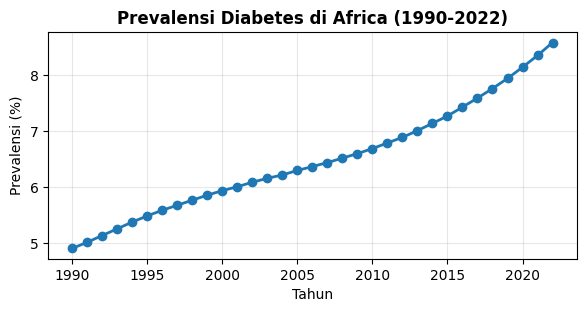

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'Africa') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - Africa")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Africa (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

DIABETES PREVALENCE FORECASTING - Americas

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        6.52
1991        6.70
1992        6.88
1993        7.05
1994        7.21

Last 5 rows:
      Prevalence
Year            
2018       13.20
2019       13.52
2020       13.86
2021       14.22
2022       14.59


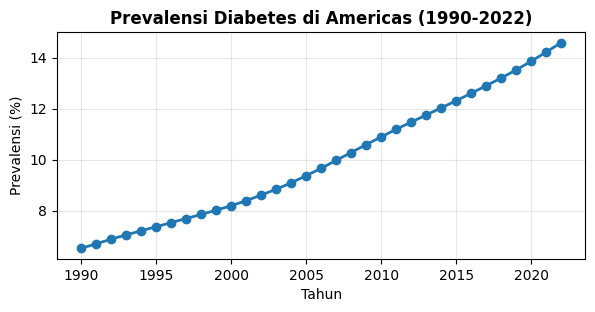

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'Americas') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - Americas")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Americas (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

DIABETES PREVALENCE FORECASTING - Eastern Mediterranean

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        8.01
1991        8.18
1992        8.39
1993        8.62
1994        8.84

Last 5 rows:
      Prevalence
Year            
2018       18.18
2019       18.72
2020       19.28
2021       19.82
2022       20.38


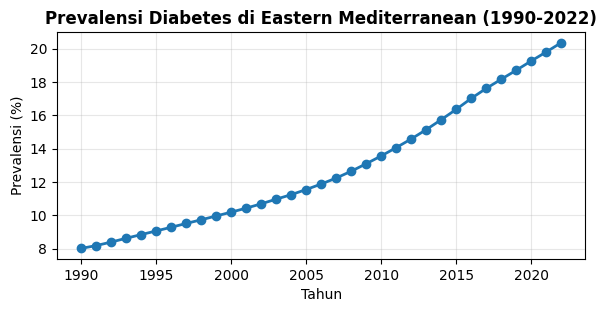

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'Eastern Mediterranean') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - Eastern Mediterranean")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Eastern Mediterranean (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

DIABETES PREVALENCE FORECASTING - Europe

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        5.58
1991        5.71
1992        5.85
1993        5.99
1994        6.14

Last 5 rows:
      Prevalence
Year            
2018       10.24
2019       10.54
2020       10.85
2021       11.18
2022       11.52


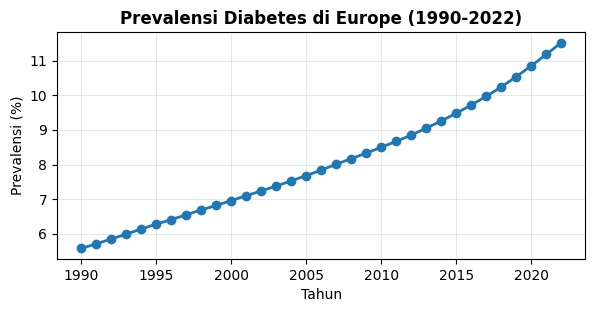

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'Europe') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - Europe")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Europe (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

DIABETES PREVALENCE FORECASTING - South-East Asia

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        8.59
1991        8.74
1992        8.90
1993        9.06
1994        9.24

Last 5 rows:
      Prevalence
Year            
2018       17.53
2019       18.20
2020       18.90
2021       19.61
2022       20.36


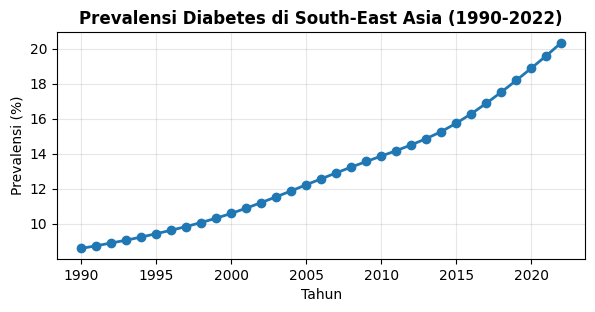

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'South-East Asia') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - South-East Asia")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di South-East Asia (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)

DIABETES PREVALENCE FORECASTING - Western Pacific

Data Overview:
Period: 1990 - 2022
Total observations: 33

First 5 rows:
      Prevalence
Year            
1990        4.63
1991        4.72
1992        4.82
1993        4.93
1994        5.05

Last 5 rows:
      Prevalence
Year            
2018       10.53
2019       11.09
2020       11.68
2021       12.29
2022       12.94


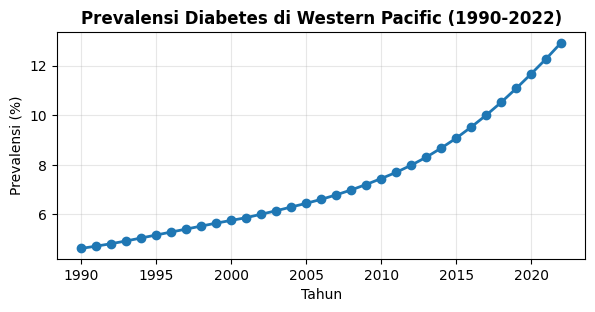

In [ ]:
# Load data
df = pd.read_csv('data (2).csv')

# Filter data untuk age-standardized prevalence, both sexes, 18+ years
df_filtered = df[
    (df['Indicator'] == 'Prevalence of diabetes, crude') &
    (df['Location'] == 'Western Pacific') &
    (df['Dim1'] == 'Both sexes') &
    (df['Dim2'] == '18+  years')
].copy()

# Sort by period
df_filtered = df_filtered.sort_values('Period')

# Prepare time series data
ts_data = df_filtered[['Period', 'FactValueNumeric']].copy()
ts_data.columns = ['Year', 'Prevalence']
ts_data = ts_data.set_index('Year')

print("="*60)
print("DIABETES PREVALENCE FORECASTING - Western Pacific")
print("="*60)
print(f"\nData Overview:")
print(f"Period: {ts_data.index.min()} - {ts_data.index.max()}")
print(f"Total observations: {len(ts_data)}")
print(f"\nFirst 5 rows:")
print(ts_data.head())
print(f"\nLast 5 rows:")
print(ts_data.tail())

# Visualisasi data asli
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.plot(ts_data.index, ts_data['Prevalence'], marker='o', linewidth=2)
plt.title('Prevalensi Diabetes di Western Pacific (1990-2022)', fontsize=12, fontweight='bold')
plt.xlabel('Tahun')
plt.ylabel('Prevalensi (%)')
plt.grid(True, alpha=0.3)